# Task 1: Temporal scRNA-seq Extrapolation (E8.5 → E9.5) | 时序单细胞外推实战

**Bilingual Chinese + English Walkthrough (`vec-t123-notebooks-cn`)**

- **目标 / Goal**: Given earlier-stage embryonic single-cell expression (`E8.5`), predict future-stage transcriptomes (`E9.5`) matching `var_names` order and `log1p` non-negative normalized expression.
- **无泄漏本地验证 / Leakage-Free Setup**: Split the pseudo-target stage cleanly into `train_fit` (used only to estimate developmental shift `Δ`) and `eval_holdout` (used strictly for metrics and visualization).
- **双模式运行 / Dual Mode**: Automatically uses `../veckit/data/` official sample `.h5ad` files if available, or self-contained synthetic data anywhere (Jupyter / Colab / CI).


In [1]:
import json, sys, tempfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "vec_nb_helpers.py").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

from vec_nb_helpers import (
    _dense_float,
    check_submission_contract,
    load_task_pair,
    predict_pseudobulk_shift,
    score_with_veckit_optional,
)

ref, target_full, source_tag = load_task_pair("T1")
print(f"Loaded T1 pair from: {source_tag}")
print(f"Reference shape: {ref.shape} | Target shape: {target_full.shape}")
print("obs columns:", list(ref.obs.columns))


Loaded T1 pair from: veckit_sample:veckit
Reference shape: (150, 32285) | Target shape: (150, 32285)
obs columns: ['celltype']


## 1. 无泄漏切分与双基线对比 / Leakage-Free Split & Baseline Comparison

对比两种最基础却差异巨大的基线：
1. **`copy_last`**: 直接复制 `E8.5` 作为 `E9.5` 预测（`de_score` 往往接近 0 分锚点）。
2. **`fit_split_shift`**: 只在 `eval_target` 之外的 `fit_target` 半折上估计基因均值漂移，并在独立留出半折 `eval_target` 上验证与可视化。


In [2]:
rng = np.random.default_rng(42)
perm = rng.permutation(target_full.n_obs)
half = target_full.n_obs // 2
fit_target = target_full[perm[:half]].copy()
eval_target = target_full[perm[half:]].copy()

x_ref = _dense_float(ref)
x_fit = _dense_float(fit_target)
x_eval = _dense_float(eval_target)

delta_fit = x_fit.mean(axis=0) - x_ref.mean(axis=0)
pred_copy = predict_pseudobulk_shift(ref, np.zeros_like(delta_fit), noise_std=0.0)
pred_shift = predict_pseudobulk_shift(ref, delta_fit, noise_std=0.0)

true_de = x_eval.mean(axis=0) - x_ref.mean(axis=0)
copy_de = _dense_float(pred_copy).mean(axis=0) - x_ref.mean(axis=0)
shift_de = _dense_float(pred_shift).mean(axis=0) - x_ref.mean(axis=0)

def pearson(a, b):
    a_c, b_c = a - a.mean(), b - b.mean()
    denom = float(np.linalg.norm(a_c) * np.linalg.norm(b_c))
    return float(np.dot(a_c, b_c) / denom) if denom > 0 else 0.0

print(f"Holdout DE Pearson(copy_last) : {pearson(true_de, copy_de):.4f}")
print(f"Holdout DE Pearson(shift_fit) : {pearson(true_de, shift_de):.4f}")
print("Contract check (pred_shift):", check_submission_contract(pred_shift, ref, require_spatial=False))


Holdout DE Pearson(copy_last) : 0.0000
Holdout DE Pearson(shift_fit) : 0.5121
Contract check (pred_shift): {'ok': True, 'n_obs': 150, 'n_vars': 32285, 'var_names_exact_match': True, 'non_negative': True, 'all_finite': True, 'spatial_3D_valid': True}


## 2. 基因差分漂移可视化 & `veckit` 本地评分 / DE Shift Plot & Local `veckit` Scoring


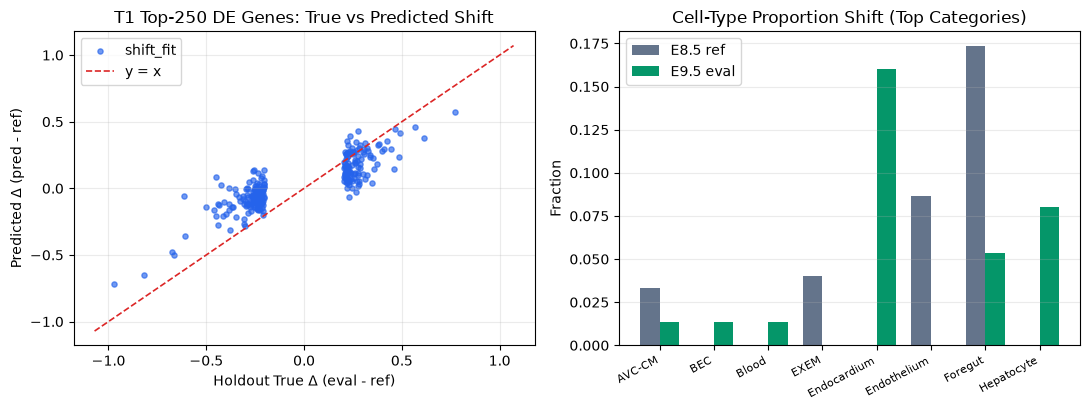

/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


veckit copy_last: {
  "de_score": 0.0,
  "de_direction": 0.0,
  "energy_distance": 0.47411,
  "mmd_u": 0.10932,
  "variogram": 0.002593,
  "pb_rel_err": 0.1448,
  "library_size_ratio": 1.0,
  "variance_ratio": 0.96,
  "composition_JSD": 0.0186,
  "pseudobulk_pearson": 0.9879,
  "_de_raw": 0.0,
  "_de_chance": 0.0,
  "_de_chance_unif": 0.0008,
  "_n_up": 12,
  "_n_dn": 13
}
veckit shift_fit: {
  "de_score": 0.44,
  "de_direction": 0.353,
  "energy_distance": 0.33124,
  "mmd_u": 0.11172,
  "variogram": 0.008936,
  "pb_rel_err": 0.1332,
  "library_size_ratio": 1.009,
  "variance_ratio": 0.924,
  "composition_JSD": 0.0245,
  "pseudobulk_pearson": 0.9903,
  "_de_raw": 0.44,
  "_de_chance": 0.0,
  "_de_chance_unif": 0.0008,
  "_n_up": 12,
  "_n_dn": 13
}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Panel A: Top differentially expressed genes scatter (True eval delta vs Predicted delta)
top_idx = np.argsort(np.abs(true_de))[-250:]
axes[0].scatter(true_de[top_idx], shift_de[top_idx], s=14, alpha=0.65, color="#2563eb", label="shift_fit")
lim = max(0.3, float(np.max(np.abs(true_de[top_idx])))) * 1.1
axes[0].plot([-lim, lim], [-lim, lim], "--", color="#dc2626", lw=1.2, label="y = x")
axes[0].set_title("T1 Top-250 DE Genes: True vs Predicted Shift")
axes[0].set_xlabel("Holdout True Δ (eval - ref)")
axes[0].set_ylabel("Predicted Δ (pred - ref)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Panel B: Celltype proportion drift between reference and eval stage
ct_ref = ref.obs["celltype"].astype(str).value_counts(normalize=True)
ct_eval = eval_target.obs["celltype"].astype(str).value_counts(normalize=True)
cts = sorted(set(ct_ref.index) | set(ct_eval.index))[:8]
x_pos = np.arange(len(cts))
axes[1].bar(x_pos - 0.18, [ct_ref.get(c, 0.0) for c in cts], width=0.36, label="E8.5 ref", color="#64748b")
axes[1].bar(x_pos + 0.18, [ct_eval.get(c, 0.0) for c in cts], width=0.36, label="E9.5 eval", color="#059669")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cts, rotation=28, ha="right", fontsize=8)
axes[1].set_title("Cell-Type Proportion Shift (Top Categories)")
axes[1].set_ylabel("Fraction")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

with tempfile.TemporaryDirectory() as tmp:
    tmp_p = Path(tmp)
    p_ref, p_tgt, p_copy, p_shift = tmp_p / "ref.h5ad", tmp_p / "tgt.h5ad", tmp_p / "copy.h5ad", tmp_p / "shift.h5ad"
    ref.write_h5ad(p_ref)
    eval_target.write_h5ad(p_tgt)
    pred_copy.write_h5ad(p_copy)
    pred_shift.write_h5ad(p_shift)
    s_copy = score_with_veckit_optional("T1", p_copy, p_tgt, p_ref)
    s_shift = score_with_veckit_optional("T1", p_shift, p_tgt, p_ref)
    if s_copy and s_shift:
        print("veckit copy_last:", json.dumps(s_copy["metrics"], indent=2))
        print("veckit shift_fit:", json.dumps(s_shift["metrics"], indent=2))
    else:
        print("veckit not installed in env — contract & holdout Pearson checks completed offline.")
